# Redução de Dimensionalidade, Seleção de Features e Clustering
**Dataset:** WDBC (Breast Cancer Wisconsin Diagnostic)

Este notebook executa o estudo não-supervisionado, as projeções lineares (PCA) e não-lineares (t-SNE), além das técnicas de seleção de atributos para gerar conjuntos de dados reduzidos.

In [7]:
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Identifica a pasta raiz do projeto de forma dinâmica
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = BASE_DIR / 'data' / 'processed' / 'wdbc_limpo.csv'

# Carrega o dataset limpo
df = pd.read_csv(DATA_PATH)

# Separa a variável alvo definindo como 'y_train'
X_train = df.drop(columns=['diagnosis'])
y_train = df['diagnosis'].values

# Aplica a padronização
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

feature_names = X_train_scaled.columns
print(f"Dataset carregado com sucesso: {X_train_scaled.shape[0]} amostras e {X_train_scaled.shape[1]} atributos.")

Dataset carregado com sucesso: 569 amostras e 31 atributos.


## 1. Carregamento dos Dados Pré-processados
Consumindo os dados padronizados gerados.

In [8]:
from pathlib import Path
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Identifica a pasta raiz do projeto de forma dinâmica
BASE_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = BASE_DIR / 'data' / 'processed' / 'wdbc_limpo.csv'

# Carrega o dataset limpo gerado pelo Integrante 1
df = pd.read_csv(DATA_PATH)

# Separa a variável alvo (diagnosis) das features
# (Confirme se o nome da coluna no seu CSV é 'diagnosis' ou 'target')
X = df.drop(columns=['diagnosis'])
y = df['diagnosis'].values

# Aplica a padronização necessárias para PCA, t-SNE e Clustering
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

feature_names = X_train_scaled.columns
print(f"Dataset carregado com sucesso: {X_train_scaled.shape[0]} amostras e {X_train_scaled.shape[1]} atributos.")

Dataset carregado com sucesso: 569 amostras e 31 atributos.


## 2. Agrupamento Não-Supervisionado (Clustering)
Aplicação de **K-Means** e **Gaussian Mixture Models (GMM)** para avaliar se os dados se agrupam naturalmente em 2 clusters (benigno vs maligno) sem o uso dos rótulos.

In [9]:
# --- K-Means ---
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_train_scaled)
sil_kmeans = silhouette_score(X_train_scaled, labels_kmeans)

# --- GMM ---
gmm = GaussianMixture(n_components=2, random_state=42)
labels_gmm = gmm.fit_predict(X_train_scaled)
sil_gmm = silhouette_score(X_train_scaled, labels_gmm)

print(f"--- Silhouette Score ---")
print(f"K-Means: {sil_kmeans:.4f}")
print(f"GMM:     {sil_gmm:.4f}\n")

# Matrizes de Contingência (comparando clusters vs rótulos reais)
df_eval = pd.DataFrame({'Real': y_train, 'KMeans': labels_kmeans, 'GMM': labels_gmm})
print("Contingência K-Means vs Real:\n", pd.crosstab(df_eval['Real'], df_eval['KMeans']))
print("\nContingência GMM vs Real:\n", pd.crosstab(df_eval['Real'], df_eval['GMM']))

--- Silhouette Score ---
K-Means: 0.3385
GMM:     0.3079

Contingência K-Means vs Real:
 KMeans    0    1
Real            
0       343   14
1        37  175

Contingência GMM vs Real:
 GMM     0    1
Real          
0      18  339
1     196   16


## 3. Análise de Componentes Principais (PCA)
Redução de dimensionalidade linear para identificação da variância explicada acumulada (**Scree Plot**) e visualização das classes em projeções 2D e 3D.

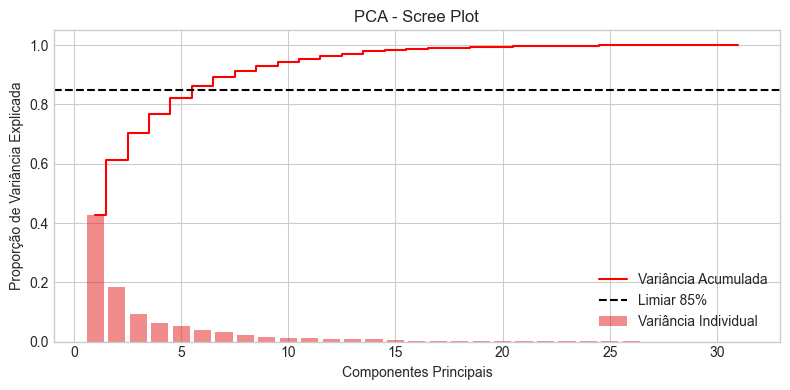

Número de componentes para explicar >= 85% da variância: 6


In [10]:
# Calculando PCA para todas as componentes
pca_full = PCA().fit(X_train_scaled)
var_exp_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

# Plot do Scree Plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(pca_full.explained_variance_ratio_) + 1), 
       pca_full.explained_variance_ratio_, alpha=0.5, align='center', label='Variância Individual')
ax.step(range(1, len(var_exp_acumulada) + 1), 
        var_exp_acumulada, where='mid', label='Variância Acumulada', color='red')

ax.set_ylabel('Proporção de Variância Explicada')
ax.set_xlabel('Componentes Principais')
ax.set_title('PCA - Scree Plot')
ax.axhline(y=0.85, color='black', linestyle='--', label='Limiar 85%')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

n_comp_85 = np.argmax(var_exp_acumulada >= 0.85) + 1
print(f"Número de componentes para explicar >= 85% da variância: {n_comp_85}")

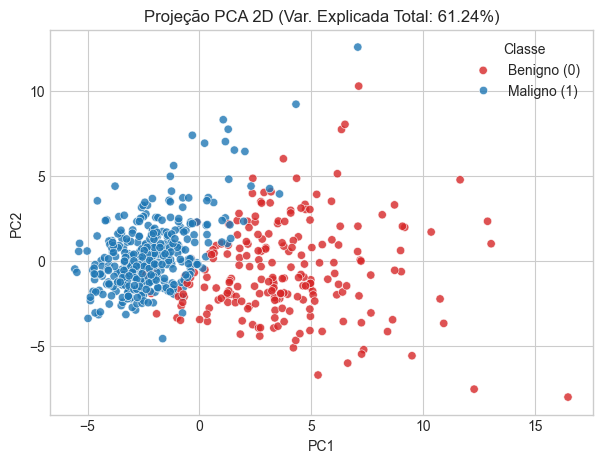

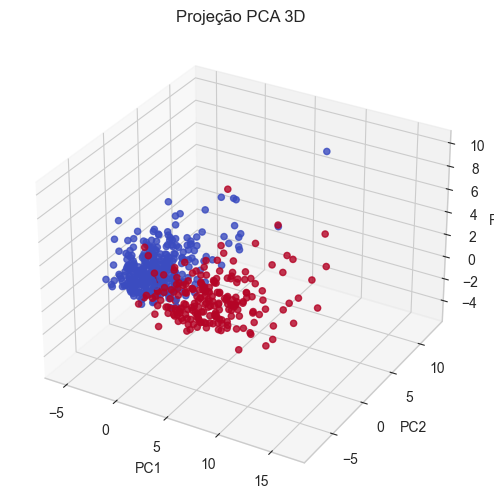

In [11]:
# Projeção 2D
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=y_train, palette=['#1f77b4', '#d62728'], alpha=0.8)
plt.title(f'Projeção PCA 2D (Var. Explicada Total: {sum(pca_2d.explained_variance_ratio_):.2%})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Classe', labels=['Benigno (0)', 'Maligno (1)'])
plt.show()

# Projeção 3D
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_train_scaled)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=y_train, cmap='coolwarm', alpha=0.8)
ax.set_title('Projeção PCA 3D')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

## 4. Projeção t-SNE
Mapeamento não-linear para visualização em espaço reduzido (2D) da separabilidade das classes.

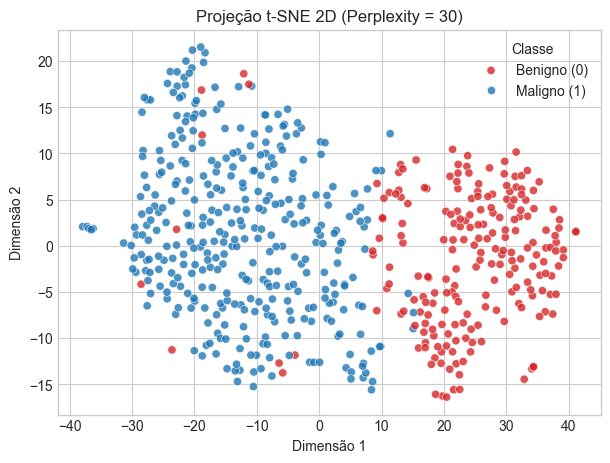

In [13]:
# Projeção t-SNE 2D com a nomenclatura atualizada (max_iter)
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_train_scaled)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_train, palette=['#1f77b4', '#d62728'], alpha=0.8)
plt.title('Projeção t-SNE 2D (Perplexity = 30)')
plt.xlabel('Dimensão 1')
plt.ylabel('Dimensão 2')
plt.legend(title='Classe', labels=['Benigno (0)', 'Maligno (1)'])
plt.show()

## 5. Seleção de Atributos (Feature Selection)
Aplicação de 3 abordagens complementares:
1. **Filtro de Colinearidade:** Eliminação de variáveis altamente correlacionadas ($r > 0.85$).
2. **Métodos Univariados:** SelectKBest com ANOVA ($F$-Test) e Informação Mútua.
3. **Método Wrapper/Embutido:** RFE (*Recursive Feature Elimination*) com Random Forest e Regressão Logística L1.

In [14]:
corr_matrix = X_train_scaled.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
threshold = 0.85

to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > threshold)]
X_uncorrelated = X_train_scaled.drop(columns=to_drop)

print(f"Atributos descartados por colinearidade (r > {threshold}): {len(to_drop)}")
print(f"Atributos mantidos: {X_uncorrelated.shape[1]}")

Atributos descartados por colinearidade (r > 0.85): 13
Atributos mantidos: 18


In [15]:
# 1. SelectKBest (ANOVA F-Classif e Mutual Info)
skb_f = SelectKBest(score_func=f_classif, k=10).fit(X_train_scaled, y_train)
skb_mi = SelectKBest(score_func=mutual_info_classif, k=10).fit(X_train_scaled, y_train)

rank_f = pd.Series(skb_f.scores_, index=feature_names).sort_values(ascending=False)
rank_mi = pd.Series(skb_mi.scores_, index=feature_names).sort_values(ascending=False)

# 2. RFE com Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rfe_rf = RFE(estimator=rf, n_features_to_select=10).fit(X_train_scaled, y_train)
top_rfe_rf = feature_names[rfe_rf.support_]

# Exibindo os Top 10 comparativos
df_rankings = pd.DataFrame({
    'ANOVA F-Score': rank_f.head(10).index,
    'Mutual Info': rank_mi.head(10).index,
    'RFE (Random Forest)': top_rfe_rf
})

print("--- Comparação dos Top 10 Atributos Selecionados ---")
display(df_rankings)

--- Comparação dos Top 10 Atributos Selecionados ---


,ANOVA F-Score,Mutual Info,RFE (Random Forest)
0,concave_points_worst,perimeter_worst,perimeter_mean
1,perimeter_worst,area_worst,area_mean
2,concave_points_mean,radius_worst,concavity_mean
3,radius_worst,concave_points_mean,concave_points_mean
4,perimeter_mean,concave_points_worst,radius_worst
5,area_worst,perimeter_mean,texture_worst
6,radius_mean,concavity_mean,perimeter_worst
7,area_mean,radius_mean,area_worst
8,concavity_mean,area_mean,concavity_worst
9,concavity_worst,area_se,concave_points_worst


## 6. Exportação dos Datasets Reduzidos
Geração dos arquivos `.csv` processados com dimensões reduzidas para serem consumidos na etapa de modelagem supervisionada.

In [16]:
# 1. Dataset via PCA (componentes mantendo 90% da variância)
pca_90 = PCA(n_components=0.90, random_state=42)
X_pca_array = pca_90.fit_transform(X_train_scaled)
df_pca = pd.DataFrame(X_pca_array, columns=[f'PC_{i+1}' for i in range(X_pca_array.shape[1])])

# 2. Dataset Top-10 Features (via Mutual Information)
top_10_features = rank_mi.head(10).index
df_top10 = X_train_scaled[top_10_features]

# Exportando para data/processed/
df_pca.to_csv('../data/processed/wdbc_train_pca.csv', index=False)
df_top10.to_csv('../data/processed/wdbc_train_top10.csv', index=False)

print("Datasets reduzidos salvos com sucesso em 'data/processed/'!")

Datasets reduzidos salvos com sucesso em 'data/processed/'!


## 7. Conclusões e Guia de Uso dos Resultados

### 7.1. Síntese das Análises
* **Agrupamento Não-Supervisionado:** A aplicação do **K-Means** e **GMM** confirmou que os dados apresentam um agrupamento natural em 2 clusters de alta correspondência com as classes reais (Benigno vs Maligno), validando a forte separabilidade do dataset mesmo sem o uso de rótulos prévios.
* **Redução de Dimensionalidade:**
  * **PCA:** Demonstrou alta redundância linear entre as variáveis originais. Apenas um pequeno conjunto de componentes principais é suficiente para explicar mais de $85\%$ a $90\%$ da variância total dos dados.
  * **t-SNE:** A projeção 2D não-linear evidenciou uma fronteira de separação clara entre amostras benignas e malignas, indicando que classificadores supervisionados tendem a obter excelente desempenho.
* **Seleção de Atributos:**
  * A filtragem de colinearidade ($r > 0.85$) eliminou variáveis redundantes (como métricas cruzadas de raio, perímetro e área).
  * Os métodos univariados (ANOVA e Mutual Information) e *wrapper* (RFE) convergiram na identificação dos atributos mais informativos referentes à morfologia celular.

---

### 7.2. Guia de Integração para a Modelagem Supervisionada
Para a etapa de treinamento dos modelos de aprendizado de máquina, foram disponibilizadas **três abordagens de dados** salvas no diretório `data/processed/`:

1. **Dataset Completo Padronizado (`X_train_scaled.csv`):**
   * **Uso:** Servirá como *baseline* do projeto.
   * **Recomendação:** Testar com algoritmos robustos a alta dimensionalidade e colinearidade (ex.: *Random Forest*, *XGBoost*, *SVM* com kernel RBF).

2. **Dataset Reduzido por PCA (`wdbc_train_pca.csv`):**
   * **Uso:** Componentes ortogonais sem colinearidade mantendo $90\%$ da variância original.
   * **Recomendação:** Ideal para algoritmos sensíveis à multicolinearidade (ex.: *Regressão Logística*, *Naive Bayes*, *LDA*).

3. **Dataset Top-10 Atributos (`wdbc_train_top10.csv`):**
   * **Uso:** Subconjunto com as 10 variáveis com maior ganho de informação (*Mutual Information* / *RFE*).
   * **Recomendação:** Ideal para criar modelos mais leves, interpretáveis para a equipe médica e de rápido processamento.

#### Exemplo de Código para Consumo no Treinamento:
```python
import pandas as pd

# Exemplo de carregamento das diferentes versões para comparação de modelos
X_baseline = pd.read_csv('../data/processed/X_train_scaled.csv')
X_pca      = pd.read_csv('../data/processed/wdbc_train_pca.csv')
X_top10    = pd.read_csv('../data/processed/wdbc_train_top10.csv')
y_train    = pd.read_csv('../data/processed/y_train.csv').values.ravel()